In [10]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score, r2_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, GradientBoostingRegressor

In [2]:
df=pd.read_csv("F:\MACHINE LEARNING\SessionsMaterial\Cases\Wisconsin\BreastCancer.csv",index_col=0)
X,y=df.drop('Class',axis=1),df['Class']
X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=26,test_size=.3,stratify=y)
df.head()

,Clump,UniCell_Size,Uni_CellShape,MargAdh,SEpith,BareN,BChromatin,NoemN,Mitoses,Class
Code,,,,,,,,,,
61634,5,4,3,1,2,2,2,3,1,Benign
63375,9,1,2,6,4,10,7,7,2,Malignant
76389,10,4,7,2,2,8,6,1,1,Malignant
95719,6,10,10,10,8,10,7,10,7,Malignant
128059,1,1,1,1,2,5,5,1,1,Benign


In [5]:
lr, dtc = LogisticRegression(), DecisionTreeClassifier(max_depth= 1, random_state= 26)
ada = AdaBoostClassifier(random_state=26, estimator= lr, n_estimators= 10)
ada.fit(X_train, y_train)
pred = ada.predict(X_test)
accuracy_score(y_test, pred)

0.9714285714285714

In [6]:
lr, dtc = LogisticRegression(), DecisionTreeClassifier(max_depth= 1, random_state= 26)
ada = AdaBoostClassifier(random_state=26, estimator= dtc, n_estimators= 10)
ada.fit(X_train, y_train)
pred = ada.predict(X_test)
accuracy_score(y_test, pred)

0.9428571428571428

In [8]:
gbm = GradientBoostingClassifier(random_state=26)
gbm.fit(X_train, y_train)
pred = gbm.predict(X_test)
accuracy_score(y_test, pred)

0.9571428571428572

In [9]:
concrete = pd.read_csv("F:\MACHINE LEARNING\SessionsMaterial\Cases\Concrete_Strength\Concrete_Data.csv")
X,y=concrete.drop('Strength',axis=1),concrete.Strength
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.3,random_state=26)
print(concrete.head())

   Cement  Blast  Fly  Water  Superplasticizer  Coarse   Fine  Age  Strength
0   540.0    0.0  0.0  162.0               2.5  1040.0  676.0   28     79.99
1   540.0    0.0  0.0  162.0               2.5  1055.0  676.0   28     61.89
2   332.5  142.5  0.0  228.0               0.0   932.0  594.0  270     40.27
3   332.5  142.5  0.0  228.0               0.0   932.0  594.0  365     41.05
4   198.6  132.4  0.0  192.0               0.0   978.4  825.5  360     44.30


In [11]:
learn_r = np.linspace(0.01, 0.9, 10)
max_depth = [None, 2,3,4]
n_est = [25,50,100]
scores = []
for r in learn_r:
    for m in max_depth:
        for n in n_est:
            gbm = GradientBoostingRegressor(random_state=26, learning_rate=r, max_depth= m, n_estimators=n)
            gbm.fit(X_train, y_train)
            pred = gbm.predict(X_test)
            scores.append([r,m,n, r2_score(y_test, pred)])
score_df=pd.DataFrame(scores,columns=["learning_rate",'max_depth','n_estimators','r2_score' ])
score_df.sort_values(by="r2_score",ascending=False,ignore_index=True)[:20]

,learning_rate,max_depth,n_estimators,r2_score
0,0.504444,3.0,100,0.927796
1,0.405556,3.0,100,0.927673
2,0.603333,2.0,100,0.927434
3,0.801111,2.0,100,0.925072
4,0.405556,2.0,100,0.924303
5,0.900000,3.0,100,0.924131
6,0.702222,3.0,100,0.923815
7,0.900000,2.0,100,0.922552
8,0.405556,4.0,100,0.921478
9,0.306667,4.0,100,0.921371


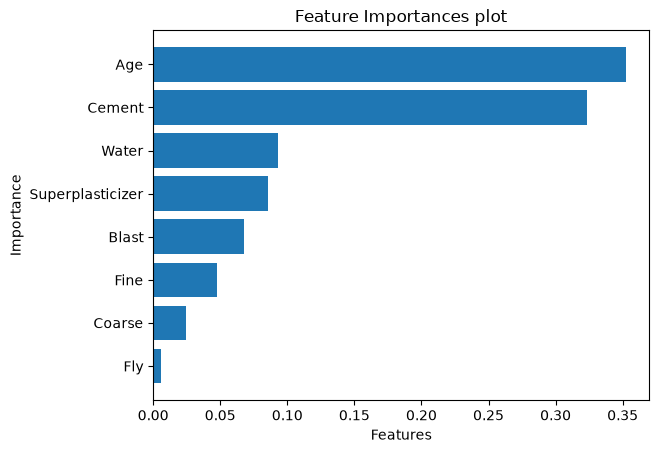

In [12]:
best_tree = GradientBoostingRegressor(random_state=26,max_depth=3, n_estimators=100, learning_rate = 0.5044)

best_tree.fit(X, y)
df_imp = pd.DataFrame({'features': list(X.columns),
                       'importance': best_tree.feature_importances_})
df_imp.sort_values('importance', inplace = True)
plt.barh(df_imp['features'], df_imp['importance'])
plt.title("Feature Importances plot")
plt.xlabel('Features')
plt.ylabel('Importance')
plt.show()